# EN3150 Assignment 03 — Model A (Standard CNN)

**Goal of this notebook:** build, train and evaluate **Model A**: standard 2D convolutions interleaved with max-pooling, as the baseline for the later comparison with Model B (depthwise separable) and the pretrained lightweight networks.

**Dataset used here:** EuroSAT RGB (10 classes, 27,000 images, native 64x64). To use another dataset, only the *Data loading* cell needs to change.

| Step | Section | Assignment part |
|---|---|---|
| 1 | Setup and configuration | - |
| 2 | Data loading, 70/15/15 split, normalisation | Data preparation |
| 3 | Model A architecture, parameter count, MACs | Part 2 |
| 4 | Training function (reusable for the optimizer study) | Parts 3 and 4 |
| 5 | Loss curves, test metrics, confusion matrix | Part 4 |
| 6 | Model size, latency, saving results for the final table | Parts 4 and 6 |

All outputs (splits, plots, weights, results JSON) go to `./outputs/` so Model B and the SOTA notebooks can reuse the **same splits**.

## 1. Setup and configuration
Fixed seeds make the splits and results reproducible. `DEVICE` falls back to CPU automatically.

In [1]:
import os, time, json, random, copy
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, precision_recall_fscore_support, accuracy_score

# ---------------- configuration ----------------
SEED       = 42
IMG_SIZE   = 64          # assignment limit: max 64x64
BATCH_SIZE = 64
EPOCHS     = 25          # assignment: at least 20
LR         = 1e-3        # Adam learning rate (optimizer study comes later)
AUGMENT    = True        # random horizontal/vertical flips (valid for satellite images)

DATA_ROOT = Path("./data")
OUT_DIR   = Path("./outputs")
OUT_DIR.mkdir(exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

set_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
torch.set_num_threads(os.cpu_count())
print("Device:", DEVICE, "| CPU threads:", torch.get_num_threads(), "| torch", torch.__version__)

Device: cpu | CPU threads: 20 | torch 2.14.1+cpu


## 2. Data preparation
**2.1 Load the dataset** into memory as a `uint8` array (about 330 MB for EuroSAT). Keeping everything in RAM avoids slow disk reads every epoch on a CPU-only machine. The array is cached as `.npz` so later notebooks load it instantly.

*If the automatic download fails*, download EuroSAT RGB manually (Kaggle / official GitHub), extract it so that the folder structure is `data/eurosat/2750/<ClassName>/*.jpg`, and re-run.

In [2]:
CACHE = OUT_DIR / "eurosat_64.npz"

if CACHE.exists():
    d = np.load(CACHE)
    X, y, CLASSES = d["X"], d["y"], [str(c) for c in d["classes"]]
    print("Loaded from cache.")
else:
    from torchvision.datasets import EuroSAT
    ds = EuroSAT(root=str(DATA_ROOT), download=True)
    CLASSES = list(ds.classes)
    X = np.stack([np.array(img.convert("RGB").resize((IMG_SIZE, IMG_SIZE))) for img, _ in ds])  # N,H,W,3 uint8
    y = np.array(ds.targets)
    np.savez_compressed(CACHE, X=X, y=y, classes=np.array(CLASSES))
    print("Downloaded, resized and cached.")

NUM_CLASSES = len(CLASSES)
print("Images:", X.shape, X.dtype, "| Labels:", y.shape, "| Classes:", NUM_CLASSES)
print(CLASSES)

Downloaded, resized and cached.
Images: (27000, 64, 64, 3) uint8 | Labels: (27000,) | Classes: 10
['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


**2.2 Stratified 70 / 15 / 15 split.** Stratification keeps the class proportions identical in train, validation and test. The indices are saved so **every model in the assignment uses exactly the same split**.

In [3]:
idx_all = np.arange(len(y))
idx_train, idx_tmp = train_test_split(idx_all, test_size=0.30, stratify=y, random_state=SEED)
idx_val, idx_test  = train_test_split(idx_tmp, test_size=0.50, stratify=y[idx_tmp], random_state=SEED)
np.savez(OUT_DIR / "splits.npz", train=idx_train, val=idx_val, test=idx_test)

print(f"Train: {len(idx_train)} ({len(idx_train)/len(y):.1%}) | Val: {len(idx_val)} ({len(idx_val)/len(y):.1%}) | Test: {len(idx_test)} ({len(idx_test)/len(y):.1%})")
print(f"\n{'Class':<24}{'Train':>8}{'Val':>8}{'Test':>8}")
for c, name in enumerate(CLASSES):
    print(f"{name:<24}{(y[idx_train]==c).sum():>8}{(y[idx_val]==c).sum():>8}{(y[idx_test]==c).sum():>8}")

Train: 18900 (70.0%) | Val: 4050 (15.0%) | Test: 4050 (15.0%)

Class                      Train     Val    Test
AnnualCrop                  2100     450     450
Forest                      2100     450     450
HerbaceousVegetation        2100     450     450
Highway                     1750     375     375
Industrial                  1750     375     375
Pasture                     1400     300     300
PermanentCrop               1750     375     375
Residential                 2100     450     450
River                       1750     375     375
SeaLake                     2100     450     450


**2.3 Tensors, normalisation and augmentation.** Mean/std are computed from the **training set only** (no leakage from validation/test). Images stay `uint8` in memory and are converted to normalised floats per batch. Augmentation (flips) is applied to **training batches only**.

In [4]:
Xt = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()   # N,3,H,W uint8
yt = torch.from_numpy(y).long()

# per-channel mean/std from the training split (computed in chunks to save RAM)
s = torch.zeros(3); s2 = torch.zeros(3); n = 0
for i in range(0, len(idx_train), 2000):
    b = Xt[idx_train[i:i+2000]].float().div(255)
    s += b.sum(dim=(0, 2, 3)); s2 += (b ** 2).sum(dim=(0, 2, 3)); n += b.shape[0] * b.shape[2] * b.shape[3]
MEAN = s / n
STD  = (s2 / n - MEAN ** 2).sqrt()
print("Train mean:", MEAN.numpy().round(4), "| std:", STD.numpy().round(4))

def prep(xb, train=False):
    xb = xb.float().div(255)
    if train and AUGMENT:
        m = torch.rand(xb.size(0)) < 0.5
        xb = torch.where(m[:, None, None, None], xb.flip(3), xb)    # horizontal flip
        m = torch.rand(xb.size(0)) < 0.5
        xb = torch.where(m[:, None, None, None], xb.flip(2), xb)    # vertical flip
    return (xb - MEAN[None, :, None, None]) / STD[None, :, None, None]

train_ds = TensorDataset(Xt[idx_train], yt[idx_train])
val_ds   = TensorDataset(Xt[idx_val],   yt[idx_val])
test_ds  = TensorDataset(Xt[idx_test],  yt[idx_test])

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(val_ds,   batch_size=256)
test_loader  = DataLoader(test_ds,  batch_size=256)
print("Batches per epoch (train):", len(train_loader))

Train mean: [0.3439 0.38   0.4075] | std: [0.2024 0.1367 0.1154]
Batches per epoch (train): 296


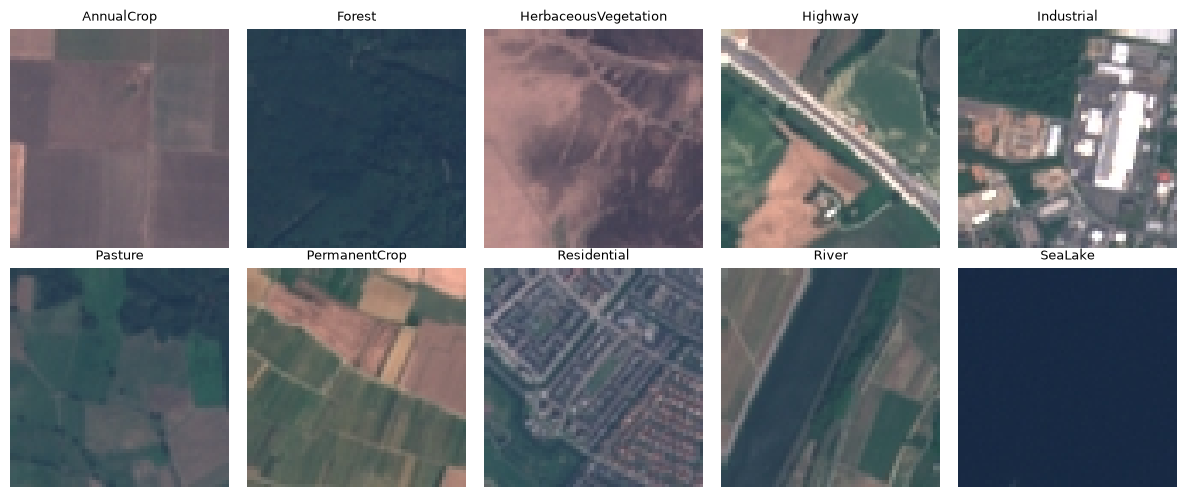

In [5]:
# quick look: one example per class
fig, axes = plt.subplots(2, (NUM_CLASSES + 1) // 2, figsize=(12, 5))
for c, ax in zip(range(NUM_CLASSES), axes.ravel()):
    ax.imshow(X[np.where(y == c)[0][0]]); ax.set_title(CLASSES[c], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.savefig(OUT_DIR / "samples.png", dpi=150); plt.show()

## 3. Model A architecture (Part 2)

**Design:** four blocks of `Conv 3x3 (same padding) -> ReLU -> MaxPool 2x2`, followed by two fully connected layers. Each pooling halves the spatial size (64 -> 32 -> 16 -> 8 -> 4) while the number of filters doubles (32 -> 64 -> 128 -> 256), the standard pattern for trading spatial resolution for feature depth.

| Layer | Kernel / units | Output shape | Parameters |
|---|---|---|---|
| Input | - | 3 x 64 x 64 | 0 |
| Conv1 + ReLU | 3x3, 32 filters | 32 x 64 x 64 | (3·3·3 + 1)·32 = **896** |
| MaxPool 2x2 | - | 32 x 32 x 32 | 0 |
| Conv2 + ReLU | 3x3, 64 filters | 64 x 32 x 32 | (3·3·32 + 1)·64 = **18,496** |
| MaxPool 2x2 | - | 64 x 16 x 16 | 0 |
| Conv3 + ReLU | 3x3, 128 filters | 128 x 16 x 16 | (3·3·64 + 1)·128 = **73,856** |
| MaxPool 2x2 | - | 128 x 8 x 8 | 0 |
| Conv4 + ReLU | 3x3, 256 filters | 256 x 8 x 8 | (3·3·128 + 1)·256 = **295,168** |
| MaxPool 2x2 | - | 256 x 4 x 4 | 0 |
| Flatten | - | 4096 | 0 |
| FC1 + ReLU (+ Dropout 0.3) | 128 units | 128 | (4096 + 1)·128 = **524,416** |
| FC2 (logits) | 10 units | 10 | (128 + 1)·10 = **1,290** |
| **Total** | | | **914,122** |

Formulas: Conv params = (k_h · k_w · C_in + 1) · C_out; FC params = (N_in + 1) · N_out.

**Activation choice (hardware-aware):** ReLU is `max(0, x)`, a single comparison with no multiplications or exponentials, so it is cheap on MCUs/Raspberry Pi and quantises well to int8. Sigmoid/tanh/Swish/GELU need `exp()` which is slow without a floating point unit or needs lookup tables. Max-pooling is also comparison-only (no arithmetic).

**Note:** the first FC layer holds about 57% of all parameters. This is typical of standard CNNs and is one of the things Model B must fix.

In [6]:
class ModelA(nn.Module):
    def __init__(self, num_classes=10, in_ch=3, img_size=64):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, kernel_size=3, padding=1),
                                 nn.ReLU(inplace=True),
                                 nn.MaxPool2d(2))
        self.features = nn.Sequential(block(in_ch, 32), block(32, 64), block(64, 128), block(128, 256))
        flat = 256 * (img_size // 16) ** 2
        self.classifier = nn.Sequential(nn.Flatten(),
                                        nn.Linear(flat, 128), nn.ReLU(inplace=True),
                                        nn.Dropout(0.3),
                                        nn.Linear(128, num_classes))
    def forward(self, x):
        return self.classifier(self.features(x))

modelA = ModelA(NUM_CLASSES, 3, IMG_SIZE)
print(modelA)

ModelA(
  (features): Sequential(
    (0): Sequential(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (1): Sequential(
      (0): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (2): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (3): Sequential(
      (0): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
      (1): ReLU(inplace=True)
      (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): L

**Layer-by-layer summary:** a forward hook records every layer's output shape, parameter count and **MACs** (multiply-accumulate operations). This should match the hand calculation above and gives the computational-cost number needed later in the Model A vs Model B comparison. The function also handles grouped/depthwise convolutions, so it can be reused for Model B.

In [7]:
def summarize(model, input_size=(1, 3, IMG_SIZE, IMG_SIZE)):
    rows, hooks = [], []
    def make_hook(name):
        def fn(m, inp, out):
            p = sum(q.numel() for q in m.parameters(recurse=False))
            if isinstance(m, nn.Conv2d):
                macs = (out.numel() // out.shape[0]) * (m.in_channels // m.groups) * m.kernel_size[0] * m.kernel_size[1]
            elif isinstance(m, nn.Linear):
                macs = m.in_features * m.out_features
            else:
                macs = 0
            rows.append((name, m.__class__.__name__, tuple(out.shape[1:]), p, macs))
        return fn
    for name, m in model.named_modules():
        if isinstance(m, (nn.Conv2d, nn.Linear, nn.MaxPool2d)):
            hooks.append(m.register_forward_hook(make_hook(name)))
    dev = next(model.parameters()).device
    was_training = model.training
    model.eval()
    with torch.no_grad():
        model(torch.zeros(input_size, device=dev))
    model.train(was_training)
    for h in hooks: h.remove()

    print(f"{'Layer':<16}{'Type':<10}{'Output shape':<18}{'Params':>10}{'MACs':>14}")
    print("-" * 68)
    for name, typ, shp, p, macs in rows:
        print(f"{name:<16}{typ:<10}{str(shp):<18}{p:>10,}{macs:>14,}")
    total_p = sum(r[3] for r in rows); total_m = sum(r[4] for r in rows)
    print("-" * 68)
    print(f"{'Total':<44}{total_p:>10,}{total_m:>14,}")
    return total_p, total_m

total_params, total_macs = summarize(modelA)
trainable = sum(p.numel() for p in modelA.parameters() if p.requires_grad)
print(f"\nTrainable parameters (PyTorch count): {trainable:,}  |  matches hand calculation (914,122): {trainable == 914122}")

Layer           Type      Output shape          Params          MACs
--------------------------------------------------------------------
features.0.0    Conv2d    (32, 64, 64)             896     3,538,944
features.0.2    MaxPool2d (32, 32, 32)               0             0
features.1.0    Conv2d    (64, 32, 32)          18,496    18,874,368
features.1.2    MaxPool2d (64, 16, 16)               0             0
features.2.0    Conv2d    (128, 16, 16)         73,856    18,874,368
features.2.2    MaxPool2d (128, 8, 8)                0             0
features.3.0    Conv2d    (256, 8, 8)          295,168    18,874,368
features.3.2    MaxPool2d (256, 4, 4)                0             0
classifier.1    Linear    (128,)               524,416       524,288
classifier.4    Linear    (10,)                  1,290         1,280
--------------------------------------------------------------------
Total                                          914,122    60,687,616

Trainable parameters (PyTorch cou

## 4. Training (Part 4)

`train_model()` takes **any model and any optimizer**, so the same function is reused in Part 3 for the Adam vs SGD vs SGD+momentum comparison, and for Model B. It records train/validation loss and accuracy, the **time per epoch**, and keeps the weights of the epoch with the best validation accuracy (the test set is never used for selection).

Loss: cross-entropy. Optimizer for the main run: **Adam, lr = 1e-3** (adaptive per-parameter step sizes, little tuning needed, fast convergence in 20-25 epochs on CPU). The formal optimizer comparison comes in the next notebook section.

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None):
    train = optimizer is not None
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for xb, yb in loader:
            xb, yb = prep(xb, train).to(DEVICE), yb.to(DEVICE)
            out = model(xb)
            loss = criterion(out, yb)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * yb.size(0)
            correct += (out.argmax(1) == yb).sum().item()
            n += yb.size(0)
    return total_loss / n, correct / n

def train_model(model, optimizer, epochs=EPOCHS, name="model"):
    criterion = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "epoch_time": []}
    best_acc, best_state = -1.0, None
    for ep in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        epoch_time = time.time() - t0                       # training time only
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(hist.keys(), (tl, vl, ta, va, epoch_time)):
            hist[k].append(v)
        if va > best_acc:
            best_acc, best_state = va, copy.deepcopy(model.state_dict())
        print(f"[{name}] epoch {ep:02d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f} | {epoch_time:.1f}s")
    model.load_state_dict(best_state)
    print(f"\nBest validation accuracy: {best_acc:.4f} | mean time/epoch: {np.mean(hist['epoch_time']):.1f}s")
    return hist

In [ ]:
set_seed(SEED)
modelA = ModelA(NUM_CLASSES, 3, IMG_SIZE).to(DEVICE)
optA = torch.optim.Adam(modelA.parameters(), lr=LR)
histA = train_model(modelA, optA, epochs=EPOCHS, name="Model A / Adam")

## 5. Results (Part 4)
**5.1 Training / validation curves.** What to look for:
- Both losses falling together means healthy learning.
- Validation loss flattening or rising while training loss keeps falling means **overfitting** (likely for a 914k-parameter model, so mention dropout and the best-validation checkpoint).
- A large gap between train and validation accuracy tells the same story.

In [ ]:
def plot_history(hist, title, fname):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(ep, hist["train_loss"], label="train"); ax[0].plot(ep, hist["val_loss"], label="validation")
    ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy loss"); ax[0].set_title(f"{title} - loss"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(ep, hist["train_acc"], label="train"); ax[1].plot(ep, hist["val_acc"], label="validation")
    ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Accuracy"); ax[1].set_title(f"{title} - accuracy"); ax[1].legend(); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150); plt.show()

plot_history(histA, "Model A (Adam, lr=1e-3)", "modelA_curves.png")

**5.2 Test-set evaluation.** The test set is used **once**, after training. Reported: overall accuracy, confusion matrix, and per-class + macro precision and recall.
- Precision = of the images predicted as class *c*, how many really are *c*.
- Recall = of the images that really are class *c*, how many were found.
- Read the confusion matrix off-diagonal: the largest off-diagonal cells are the class pairs the network confuses, which is what the discussion should explain.

In [ ]:
def predict(model, loader):
    model.eval(); ys, ps = [], []
    with torch.no_grad():
        for xb, yb in loader:
            ps.append(model(prep(xb).to(DEVICE)).argmax(1).cpu()); ys.append(yb)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

y_true, y_pred = predict(modelA, test_loader)
test_acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
print(f"Test accuracy: {test_acc:.4f}")
print(f"Macro precision: {prec:.4f} | Macro recall: {rec:.4f} | Macro F1: {f1:.4f}\n")
print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4, zero_division=0))

In [ ]:
def plot_confusion(y_true, y_pred, title, fname):
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(8, 7))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(NUM_CLASSES)); ax.set_yticks(range(NUM_CLASSES))
    ax.set_xticklabels(CLASSES, rotation=45, ha="right"); ax.set_yticklabels(CLASSES)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(title)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    plt.colorbar(im); plt.tight_layout(); plt.savefig(OUT_DIR / fname, dpi=150); plt.show()
    return cm

cmA = plot_confusion(y_true, y_pred, f"Model A - confusion matrix (test acc {test_acc:.2%})", "modelA_confusion.png")

# the most confused class pairs (largest off-diagonal entries)
off = cmA.copy(); np.fill_diagonal(off, 0)
print("Most confused pairs (true -> predicted : count)")
for k in np.argsort(off.ravel())[::-1][:5]:
    i, j = divmod(k, NUM_CLASSES)
    if off[i, j] > 0: print(f"  {CLASSES[i]} -> {CLASSES[j]} : {off[i, j]}")

## 6. Deployment metrics for the comparison table
- **Model size on disk (KB):** size of the saved `state_dict` file (float32 weights: about 4 bytes per parameter).
- **Latency:** average CPU time for a single 64x64 image (batch size 1), which is what an edge device would actually see. This is measured on your laptop, so use it only for *relative* comparison between models.
- **MACs:** from the summary above (computational cost).

Everything is saved to `outputs/modelA_results.json` so the final table (Model A vs Model B vs SOTA) can be built without re-running anything.

In [ ]:
# model size on disk
torch.save(modelA.state_dict(), OUT_DIR / "modelA.pt")
size_kb = os.path.getsize(OUT_DIR / "modelA.pt") / 1024
print(f"Model A size on disk: {size_kb:.1f} KB ({size_kb/1024:.2f} MB) | theoretical float32: {total_params*4/1024:.1f} KB")

# single-image CPU latency
modelA_cpu = copy.deepcopy(modelA).to("cpu").eval()
x1 = prep(Xt[idx_test[:1]])
with torch.no_grad():
    for _ in range(20): modelA_cpu(x1)                         # warm-up
    t0 = time.perf_counter()
    for _ in range(200): modelA_cpu(x1)
latency_ms = (time.perf_counter() - t0) / 200 * 1000
print(f"CPU latency (batch 1): {latency_ms:.2f} ms/image")

results = {
    "model": "Model A (standard CNN)", "optimizer": "Adam", "lr": LR, "epochs": EPOCHS,
    "params": int(total_params), "macs": int(total_macs), "size_kb": round(size_kb, 1),
    "time_per_epoch_s": round(float(np.mean(histA["epoch_time"])), 2),
    "latency_ms_cpu": round(latency_ms, 2),
    "best_val_acc": float(max(histA["val_acc"])),
    "test_acc": float(test_acc), "macro_precision": float(prec), "macro_recall": float(rec), "macro_f1": float(f1),
    "history": histA,
}
with open(OUT_DIR / "modelA_results.json", "w") as f:
    json.dump(results, f, indent=2)
print(json.dumps({k: v for k, v in results.items() if k != "history"}, indent=2))

## 7. Interpretation guide for the report (fill with your actual numbers)

**Part 2 - Architecture:** include the layer table from Section 3 and state the total of **914,122** trainable parameters (it should match the printed count). Justify ReLU + max-pooling with the hardware argument (comparisons only, no exponentials, int8-friendly). State that FC1 dominates the parameter budget.

**Part 4 - Results for Model A:**
1. Convergence: epoch at which validation accuracy plateaus; train-validation gap = overfitting evidence.
2. Test accuracy, macro precision and recall (quote the numbers printed above).
3. Confusion matrix: name the 2-3 most confused class pairs and give a *visual* reason (for EuroSAT: Highway vs River vs Pasture, or Permanent Crop vs Herbaceous Vegetation).
4. Cost numbers for the comparison table: parameters, size (KB), mean time/epoch, MACs, CPU latency.

**Next notebook sections:**
- **Part 3:** re-create `ModelA`, then call `train_model()` with `torch.optim.SGD(lr=...)`, `torch.optim.SGD(lr=..., momentum=0.9)` and Adam, and plot all validation-loss curves on one figure (also try momentum 0.5 / 0.9 / 0.99 for the momentum-impact discussion).
- **Model B:** replace each `Conv2d` with depthwise (`groups=C_in`) + pointwise 1x1, keep total params below 100,000, and reuse `splits.npz`, `prep()`, `train_model()`, `summarize()`.
- **Part 5:** fine-tune two pretrained nets on the same split (ImageNet mean/std normalisation, replace the classifier head).